# **멀티모달 LLM**


---




| 항목 | 내용 |
|---|---|
| 런타임 | Colab **T4 GPU** 권장 |
| 외부 API | **필요 없음** — 오픈 모델(ViT, CLIP, BLIP, Qwen3-VL)만 사용. 마지막 선택 셀만 Gemini API |
| 실습 구성 | 실습 1 패치 토큰 → 실습 2 CLIP 대조 손실 → 실습 3 CLIP 제로샷·BLIP 캡션 → 실습 4 VLM 질의응답·환각 점검 → 실습 5 멀티모달 RAG |





**핵심 질문**
> Q1. 기계는 사진을 어떻게 '읽을' 수 있을까? — 이미지는 어떻게 토큰이 되는가

> Q2. '강아지'라는 단어와 강아지 사진은 어떻게 같은 의미로 연결될까?

> Q3. 멀티모달 LLM은 사진을 보고 어떻게 문장을 '생성'할까? 그리고 그 답을 믿어도 될까?

## **0. 환경 준비** · 예제 이미지

In [1]:
!pip install -q "transformers>=4.57" accelerate pillow matplotlib

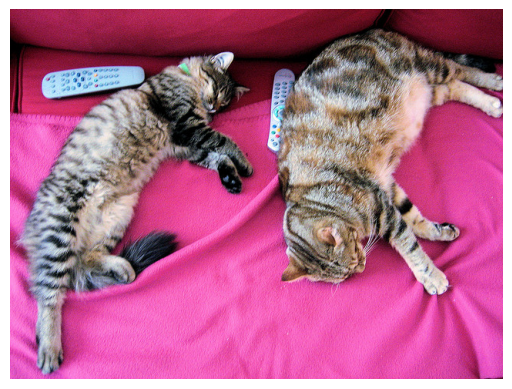

(640, 480)


In [2]:
import io, requests
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Hugging Face 문서에서 널리 쓰는 COCO 검증 이미지(소파 위 고양이 두 마리)
URL = "http://images.cocodataset.org/val2017/000000039769.jpg"
cat_img = Image.open(io.BytesIO(requests.get(URL, timeout=30).content)).convert("RGB")
# 내 사진을 쓰려면: from google.colab import files; cat_img = Image.open(list(files.upload())[0]).convert("RGB")
plt.imshow(cat_img); plt.axis("off"); plt.show()
print(cat_img.size)

---
## **[실습 1] 이미지 → 패치 토큰 직접 만들기**

ViT(Dosovitskiy et al., 2020)는 이미지를 $P\times P$ 패치로 잘라 한 줄로 펴고 선형 변환합니다.

$$N = \frac{H \cdot W}{P^2}, \qquad \mathbf{z}_0 = [\mathbf{x}_{cls};\ \mathbf{x}_p^1\mathbf{E};\ \dots;\ \mathbf{x}_p^N\mathbf{E}] + \mathbf{E}_{pos}, \quad \mathbf{E}\in\mathbb{R}^{(P^2 C)\times D}$$

In [3]:
import numpy as np

def patchify(img, P=16):
    '''(H, W, C) 이미지 → (N, P*P*C) 패치 행렬'''
    H, W, C = img.shape
    assert H % P == 0 and W % P == 0, "H, W는 P의 배수여야 함"
    x = img.reshape(H // P, P, W // P, P, C)      # 세로 블록, 세로 픽셀, 가로 블록, 가로 픽셀, 채널
    x = x.transpose(0, 2, 1, 3, 4)                # 블록끼리 모으기
    return x.reshape(-1, P * P * C)

img = np.random.rand(224, 224, 3).astype("float32")
patches = patchify(img, 16)
print("패치 행렬:", patches.shape)                 # (196, 768)

# 선형 투영 E : 768 → D(=768) — ViT-Base의 임베딩 차원
rng = np.random.default_rng(0)
E = rng.normal(0, 0.02, size=(768, 768)).astype("float32")
tokens = patches @ E
print("패치 토큰:", tokens.shape, "→ [CLS] 1개를 더하면", tokens.shape[0] + 1, "개")

# 해상도·패치 크기에 따른 토큰 수와 어텐션 비용(N^2)
print(f"{'해상도':>8} {'P':>3} {'토큰 N':>7} {'N^2(어텐션)':>12}")
for H, P in [(224, 16), (384, 16), (512, 16), (224, 14), (336, 14)]:
    N = (H // P) ** 2
    print(f"{H:>5}x{H:<3} {P:>3} {N:>7} {N*N:>12,}")

패치 행렬: (196, 768)
패치 토큰: (196, 768) → [CLS] 1개를 더하면 197 개
     해상도   P    토큰 N     N^2(어텐션)
  224x224  16     196       38,416
  384x384  16     576      331,776
  512x512  16    1024    1,048,576
  224x224  14     256       65,536
  336x336  14     576      331,776


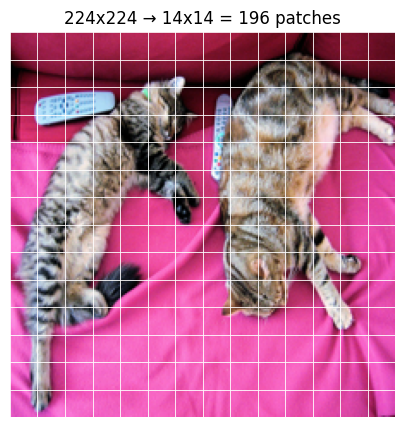

In [4]:
# 실제 사진을 16x16 패치 격자로 보기
im = np.asarray(cat_img.resize((224, 224))) / 255.0
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(im)
for t in range(0, 225, 16):
    ax.axhline(t - 0.5, color="w", lw=0.6); ax.axvline(t - 0.5, color="w", lw=0.6)
ax.set_title("224x224 → 14x14 = 196 patches"); ax.axis("off"); plt.show()

**미션 & 체크포인트**
- 해상도를 224 → 512로 올리면 토큰 수는 몇 배, 어텐션 계산량($N^2$)은 몇 배가 되는가?
- `patchify`로 만든 첫 번째 패치를 다시 16×16×3으로 reshape해 원본 왼쪽 위 조각과 같은지 확인하자.
- ★ 이미지 태깅 실습은 `_11_ml_멀티모달LLM_2_ViT로_이미지_자동_태깅하기_완성.ipynb` 에서 이어서 진행

---
## **[실습 2] CLIP 대조 손실(InfoNCE)을 직접 계산하기**

배치에 이미지-문장 쌍 $N$개가 있을 때 유사도 행렬 $S_{ij} = \dfrac{\mathbf{I}_i\cdot\mathbf{T}_j}{\tau}$ (정규화된 벡터)
$$\mathcal{L} = \tfrac{1}{2}\Big[\underbrace{\mathrm{CE}(S,\ \text{정답}=i)}_{\text{이미지→문장}} + \underbrace{\mathrm{CE}(S^\top,\ \text{정답}=i)}_{\text{문장→이미지}}\Big]$$
대각선(짝)은 가깝게, 나머지 $N^2-N$ 칸은 멀게 — Radford et al., 2021

In [5]:
import torch
import torch.nn.functional as F

def clip_loss(img_emb, txt_emb, tau=0.07):
    '''CLIP의 대칭 대조 손실'''
    I = F.normalize(img_emb, dim=-1)
    T = F.normalize(txt_emb, dim=-1)
    S = I @ T.t() / tau                      # (N, N) 유사도 행렬
    target = torch.arange(S.size(0))         # i번째 이미지의 짝은 i번째 문장
    return (F.cross_entropy(S, target) + F.cross_entropy(S.t(), target)) / 2, S

torch.manual_seed(0)
N, D = 4, 8
txt = torch.randn(N, D)
img_random = torch.randn(N, D)               # ① 학습 전: 서로 무관한 벡터
img_aligned = txt + 0.1 * torch.randn(N, D)  # ② 학습 후: 짝끼리 거의 같은 방향

for name, img in [("학습 전(무작위)", img_random), ("학습 후(정렬)", img_aligned)]:
    for tau in [1.0, 0.07]:
        loss, S = clip_loss(img, txt, tau)
        print(f"{name:<12} tau={tau:<5} loss = {loss.item():.4f}")
print("기준선 log(N) =", round(float(np.log(N)), 4), "← 모든 문장 확률이 1/N로 같을 때의 손실")

학습 전(무작위)    tau=1.0   loss = 1.4800
학습 전(무작위)    tau=0.07  loss = 5.1350
학습 후(정렬)     tau=1.0   loss = 0.8587
학습 후(정렬)     tau=0.07  loss = 0.0092
기준선 log(N) = 1.3863 ← 모든 문장 확률이 1/N로 같을 때의 손실


In [6]:
# 온도 τ의 역할: 작을수록 확률이 '뾰족'해진다
loss, _ = clip_loss(img_aligned, txt)
for tau in [1.0, 0.3, 0.07, 0.01]:
    _, S = clip_loss(img_aligned, txt, tau)
    print(f"tau={tau:<5} 첫 번째 이미지의 문장 확률:", np.round(S[0].softmax(-1).numpy(), 3))

tau=1.0   첫 번째 이미지의 문장 확률: [0.412 0.215 0.129 0.243]
tau=0.3   첫 번째 이미지의 문장 확률: [0.764 0.088 0.016 0.132]
tau=0.07  첫 번째 이미지의 문장 확률: [0.999 0.    0.    0.001]
tau=0.01  첫 번째 이미지의 문장 확률: [1. 0. 0. 0.]


In [7]:
# 작은 '미니 CLIP' 학습: 두 개의 선형 인코더가 짝을 맞추도록 학습된다
torch.manual_seed(1)
N, d_img, d_txt, D = 32, 20, 12, 8
Z = torch.randn(N, 4)                                    # 이미지·문장이 공유하는 '진짜 의미'
x_img = Z @ torch.randn(4, d_img) + 0.1 * torch.randn(N, d_img)
x_txt = Z @ torch.randn(4, d_txt) + 0.1 * torch.randn(N, d_txt)
f_img, f_txt = torch.nn.Linear(d_img, D), torch.nn.Linear(d_txt, D)
opt = torch.optim.Adam(list(f_img.parameters()) + list(f_txt.parameters()), lr=0.05)
for step in range(201):
    loss, S = clip_loss(f_img(x_img), f_txt(x_txt))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0:
        acc = (S.argmax(1) == torch.arange(N)).float().mean().item()
        print(f"step {step:3d}  loss={loss.item():.3f}  이미지→문장 정답률={acc:.2f}")

step   0  loss=4.911  이미지→문장 정답률=0.03
step  50  loss=0.211  이미지→문장 정답률=1.00
step 100  loss=0.160  이미지→문장 정답률=1.00
step 150  loss=0.146  이미지→문장 정답률=1.00
step 200  loss=0.139  이미지→문장 정답률=1.00


**미션 & 체크포인트**
- 무작위 벡터일 때 τ=1이면 손실이 $\log N$ 근처다. 왜일까? (모든 문장 확률이 $1/N$이면 CE $= \log N$)
- 같은 무작위 벡터인데 τ=0.07이면 손실이 훨씬 크다 — '자신 있게 틀리는' 상황이기 때문
- ★ 배치 크기 $N$을 키우면 문제가 어려워지는가 쉬워지는가? CLIP은 왜 배치 32,768을 썼을까?
- 1부 RAG의 밀집 검색기(DPR·E5)도 **같은 형태의 대조 손실**로 학습된다 — 연결해서 설명해 보자.

---
## **[실습 3] CLIP 제로샷 분류 · 프롬프트 앙상블 · BLIP 캡션**
제로샷 분류도 결국 **프롬프트 엔지니어링**입니다. 라벨 단어만 넣을 때와 문장 템플릿을 넣을 때를 비교합니다.

In [13]:
import torch
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

labels = ["cat", "dog", "remote control", "sofa", "laptop"]
templates = ["{}", "a photo of a {}.", "a blurry photo of a {}.", "a close-up photo of a {}."]

@torch.no_grad()
def text_emb(texts):
    inputs = cproc(text=texts, return_tensors="pt", padding=True)
    outputs = clip.get_text_features(**inputs)
    # BaseModelOutputWithPooling 또는 텐서 반환 모두 지원되도록 처리
    if hasattr(outputs, "text_embeds"):
        t = outputs.text_embeds
    elif hasattr(outputs, "pooler_output"):
        t = outputs.pooler_output
    elif isinstance(outputs, torch.Tensor):
        t = outputs
    else:
        t = outputs[0]
    return t / t.norm(dim=-1, keepdim=True)

@torch.no_grad()
def image_emb(imgs):
    inputs = cproc(images=imgs, return_tensors="pt")
    outputs = clip.get_image_features(**inputs)
    # BaseModelOutputWithPooling 또는 텐서 반환 모두 지원되도록 처리
    if hasattr(outputs, "image_embeds"):
        v = outputs.image_embeds
    elif hasattr(outputs, "pooler_output"):
        v = outputs.pooler_output
    elif isinstance(outputs, torch.Tensor):
        v = outputs
    else:
        v = outputs[0]
    return v / v.norm(dim=-1, keepdim=True)

v = image_emb([cat_img])[0]
scale = clip.logit_scale.exp().item()          # 학습된 1/τ (약 100)
for tpl in templates[:2]:
    p = (scale * text_emb([tpl.format(l) for l in labels]) @ v).softmax(-1)
    print(f"템플릿 '{tpl}':", {l: round(x, 3) for l, x in zip(labels, p.tolist())})

# 프롬프트 앙상블: 템플릿별 텍스트 임베딩의 평균을 라벨 대표 벡터로
ens = torch.stack([text_emb([t.format(l) for t in templates]).mean(0) for l in labels])
ens = ens / ens.norm(dim=-1, keepdim=True)
print("앙상블:", {l: round(x, 3) for l, x in zip(labels, (scale * ens @ v).softmax(-1).tolist())})

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

템플릿 '{}': {'cat': 0.109, 'dog': 0.001, 'remote control': 0.553, 'sofa': 0.313, 'laptop': 0.025}
템플릿 'a photo of a {}.': {'cat': 0.543, 'dog': 0.002, 'remote control': 0.299, 'sofa': 0.133, 'laptop': 0.022}
앙상블: {'cat': 0.279, 'dog': 0.001, 'remote control': 0.362, 'sofa': 0.324, 'laptop': 0.034}


In [14]:
from transformers import BlipProcessor, BlipForConditionalGeneration

bproc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")

for prefix in [None, "a photography of"]:          # 조건 없는 캡션 / 시작 문구를 준 캡션
    inp = bproc(cat_img, prefix, return_tensors="pt") if prefix else bproc(cat_img, return_tensors="pt")
    out = blip.generate(**inp, max_new_tokens=30)
    print(f"[{prefix or '조건 없음'}]", bproc.decode(out[0], skip_special_tokens=True))

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

[조건 없음] two cats sleeping on a couch
[a photography of] a photography of two cats sleeping on a couch


**미션 & 체크포인트**
- 'cat'만 넣었을 때와 'a photo of a cat.'일 때 확률이 어떻게 달라졌는가? 앙상블은?
- CLIP은 후보가 있어야 고르고, BLIP은 후보 없이 문장을 만든다 — 각각 어떤 서비스에 맞는가?
- ★ 후보 목록에 정답이 없으면 CLIP은 무엇을 고르는가? (소프트맥스는 '모름'을 말하지 못한다)

---
## **[실습 4] 오픈 VLM(Qwen3-VL)으로 이미지 질의응답 + 환각 점검**
구조: **비전 인코더 → 연결층(projector) → LLM**. 이미지가 몇 개의 토큰이 되는지도 직접 셉니다.

In [15]:
from transformers import AutoProcessor, AutoModelForImageTextToText

VLM_ID = "Qwen/Qwen3-VL-2B-Instruct"            # Apache-2.0, T4 GPU에서 실행 가능한 크기
vproc = AutoProcessor.from_pretrained(VLM_ID)
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype="auto", device_map="auto")

def ask(image, question, max_new_tokens=256):
    msgs = [{"role": "user", "content": [{"type": "image", "image": image},
                                         {"type": "text", "text": question}]}]
    inputs = vproc.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt").to(vlm.device)
    with torch.no_grad():
        out = vlm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    ans = vproc.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]
    return ans, inputs

ans, inputs = ask(cat_img, "이 사진을 한국어 두 문장으로 설명해줘.")
print(ans)
pad_id = vproc.tokenizer.convert_tokens_to_ids("<|image_pad|>")
print("이미지가 차지한 토큰 수:", int((inputs["input_ids"] == pad_id).sum()),
      "/ 전체 입력 토큰:", inputs["input_ids"].shape[1])

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

1. 두 마리의 고양이가 핑크색 소파에 누워서 휴식을 취하고 있습니다.
2. 고양이들은 각각 다른 방향으로 누워 있으며, 각각의 고양이 옆에는 릴레이 컨트롤러가 놓여 있습니다.
이미지가 차지한 토큰 수: 300 / 전체 입력 토큰: 323


In [16]:
# 환각 점검 (POPE 방식: 있는 물체 / 없는 물체를 예·아니오로 묻기 — Li et al., 2023)
probes = {"고양이": True, "리모컨": True, "강아지": False, "사람": False, "노트북 컴퓨터": False}
correct = 0
for obj, truth in probes.items():
    a, _ = ask(cat_img, f"이 사진에 {obj}이(가) 있나요? '예' 또는 '아니오'로만 답하세요.", 8)
    pred = a.strip().startswith("예")
    correct += (pred == truth)
    print(f"{obj:<8} 정답={'예' if truth else '아니오':<4} 모델={a.strip()}")
print(f"정확도 {correct}/{len(probes)}")

# 구조화 출력: 프로그램이 쓰기 좋은 JSON으로
print(ask(cat_img, '사진 속 물체를 JSON 배열로만 출력해. 형식: [{"name": "...", "count": 숫자}]')[0])

고양이      정답=예    모델=예
리모컨      정답=예    모델=예
강아지      정답=아니오  모델=아니오
사람       정답=아니오  모델=아니오
노트북 컴퓨터  정답=아니오  모델=아니오
정확도 5/5
```json
[
	{"name": "고양이", "count": 2},
	{"name": "remote", "count": 2}
]
```


**미션 & 체크포인트**
- 이미지 크기를 절반으로 줄여 다시 물어보자. 이미지 토큰 수와 답의 품질이 어떻게 변하는가?
- 없는 물체를 '예'라고 답한 경우가 있었는가? → **시각 환각**. 서비스라면 어떻게 막을까?
- ★ 같은 질문을 영어로 하면 정확도가 달라지는가?

---
## **[실습 5] 멀티모달 RAG — 이미지까지 검색해서 답하는 '자료 봇'**
① CLIP으로 이미지 인덱스 만들기 → ② 텍스트 질문으로 가장 가까운 이미지 검색 → ③ 찾은 이미지를 VLM에 넣어 답 생성
(1부 RAG와 같은 구조 — 검색 대상만 이미지로 바뀜)

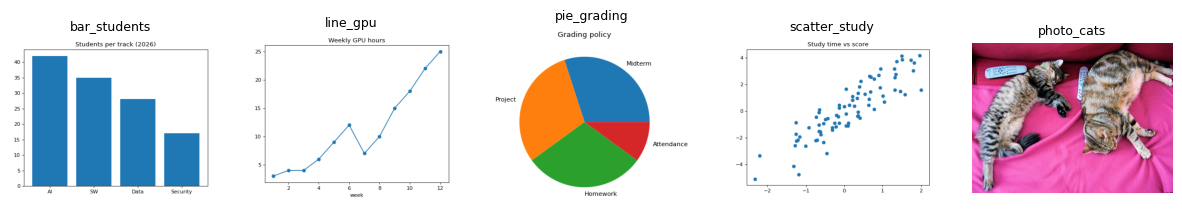

In [17]:
# 검색 대상 '자료' 만들기: 그래프 4장 + 사진 1장 (외부 파일 없이 코드로 생성)
def fig_to_img(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=80, bbox_inches="tight"); plt.close(fig)
    return Image.open(buf).convert("RGB")

library = {}
fig, ax = plt.subplots()
ax.bar(["AI", "SW", "Data", "Security"], [42, 35, 28, 17], color="tab:blue")
ax.set_title("Students per track (2026)")
library["bar_students"] = fig_to_img(fig)

fig, ax = plt.subplots()
ax.plot(range(1, 13), [3, 4, 4, 6, 9, 12, 7, 10, 15, 18, 22, 25], marker="o")
ax.set_title("Weekly GPU hours")
ax.set_xlabel("week")
library["line_gpu"] = fig_to_img(fig)

fig, ax = plt.subplots()
ax.pie([30, 30, 30, 10], labels=["Midterm", "Project", "Homework", "Attendance"])
ax.set_title("Grading policy")
library["pie_grading"] = fig_to_img(fig)

fig, ax = plt.subplots()
r = np.random.default_rng(0)
xs = r.normal(size=80)
ax.scatter(xs, 2 * xs + r.normal(size=80)); ax.set_title("Study time vs score")
library["scatter_study"] = fig_to_img(fig)
library["photo_cats"] = cat_img

names = list(library)
fig, axes = plt.subplots(1, len(names), figsize=(15, 3))
for a, n in zip(axes, names):
    a.imshow(library[n]); a.set_title(n, fontsize=9); a.axis("off")
plt.show()

In [19]:
V = image_emb([library[n] for n in names])          # 이미지 인덱스 (정규화된 CLIP 벡터)

def search_images(query, k=2):
    q = text_emb([query])[0]
    s = (V @ q).tolist()
    order = sorted(range(len(names)), key=lambda i: -s[i])[:k]
    return [(names[i], round(s[i], 3)) for i in order]

for q in ["a pie chart", "a line graph going up", "cats sleeping on a couch", "a bar chart"]:
    print(f"{q:<28} →", search_images(q))

a pie chart                  → [('pie_grading', 0.269), ('line_gpu', 0.191)]
a line graph going up        → [('line_gpu', 0.272), ('bar_students', 0.253)]
cats sleeping on a couch     → [('photo_cats', 0.289), ('scatter_study', 0.148)]
a bar chart                  → [('scatter_study', 0.253), ('bar_students', 0.249)]


In [20]:
def multimodal_rag(question_ko, query_en):
    '''질문(한국어) + 검색어(영어: CLIP이 영어로 학습됨) → 이미지 검색 → VLM 답변'''
    top_name, score = search_images(query_en, k=1)[0]
    prompt = (f"다음 자료 이미지를 근거로 질문에 답하세요. 이미지에서 읽을 수 없는 값은 "
              f"'판독 불가'라고 쓰세요.\n질문: {question_ko}")
    ans, _ = ask(library[top_name], prompt)
    print(f"검색된 자료: {top_name} (유사도 {score})\n답: {ans}\n")

multimodal_rag("성적 평가에서 출석 비중은 몇 퍼센트인가요?", "a pie chart of grading policy")
multimodal_rag("GPU 사용 시간이 가장 많은 주차는?", "a line graph")

검색된 자료: pie_grading (유사도 0.361)
답: 이 이미지에서 출석 비중은 10%입니다.

검색된 자료: line_gpu (유사도 0.286)
답: GPU 사용 시간이 가장 많은 주차는 12주차입니다.



**미션 & 체크포인트**
- 한국어 검색어("원 그래프")로 검색하면 결과가 어떻게 되는가? → 다국어 인코더(예: SigLIP 2) 또는 '질문 번역' 단계가 필요한 이유
- 그래프 속 숫자를 VLM이 정확히 읽었는가? 원본 값과 대조하자 (판독 오류는 조용히 발생한다).
- ★ 텍스트 RAG(1부)와 이미지 RAG를 합치는 설계도를 그려 보자 — 기말 프로젝트 아이디어로 발전

---
## **[선택] Gemini API로 도표·문서 읽히기**
- 왼쪽 🔑 **보안 비밀**에 `GEMINI_API_KEY` 등록 → 노트북 액세스 켜기
- 2026-11 공식 문서의 Interactions API 형식(이미지: `type`/`data`/`mime_type`). **모델 이름은 강의 전 [모델 목록](https://ai.google.dev/gemini-api/docs/models)에서 재확인**


In [ ]:
!pip install -q -U google-genai
import base64
from google import genai
from google.colab import userdata

GEMINI_MODEL = "gemini-3.8-flash"     # 2026-11 문서 예제 기준 — 바뀌었으면 수정
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

buf = io.BytesIO(); library["bar_students"].save(buf, format="PNG")
res = client.interactions.create(
    model=GEMINI_MODEL,
    input=[{"type": "text", "text": "이 그래프의 수치를 마크다운 표로 옮기고, 읽을 수 없는 값은 '판독 불가'로 표시해."},
           {"type": "image", "data": base64.b64encode(buf.getvalue()).decode(), "mime_type": "image/png"}])
print(res.output_text)

---
## 정리

| 핵심 질문 | 오늘 실습에서 확인한 답 |
|---|---|
| Q1. 기계는 사진을 어떻게 읽나 | 패치로 잘라 벡터로 바꾸면 이미지도 '토큰열'이 된다 (실습 1, 실습 4의 이미지 토큰 수) |
| Q2. 단어와 사진은 어떻게 연결되나 | 대조학습으로 짝은 가깝게, 아닌 것은 멀게 — 같은 벡터 공간에 정렬 (실습 2·3) |
| Q3. 어떻게 생성하고, 믿어도 되나 | 이미지 토큰을 LLM 입력에 연결해 다음 토큰을 생성. 단, 시각 환각이 있으므로 검증 필요 (실습 4·5) |